# Section II — Fine-tuning DistilBERT for IT ticket routing
Runtime → Change runtime type → **T4 GPU**. Upload the repo zip or clone your GitHub repo first.

In [1]:
!unzip -q servicedesk-copilot.zip
%cd servicedesk-copilot
!pip -q install -r finetune/requirements.txt

/content/servicedesk-copilot
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


## 1. Prepare data (screenshot the class distribution for the report)

In [2]:
!python finetune/prepare_data.py --top-queues 8 --max-per-class 1500

README.md: 7.75kB [00:00, 2.01MB/s]
aa_dataset-tickets-multi-lang-5-2-50-ver(…): 100% 26.0M/26.0M [00:01<00:00, 13.9MB/s]
(…)set-tickets-german_normalized_50_5_2.csv: 8.33MB [00:00, 149MB/s]
dataset-tickets-multi-lang-4-20k.csv: 100% 18.8M/18.8M [00:00<00:00, 19.7MB/s]
Generating train split: 100% 61765/61765 [00:01<00:00, 59000.14 examples/s]
Raw rows: 61765
/content/servicedesk-copilot/finetune/prepare_data.py:33: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df = df.groupby("queue", group_keys=False).apply(lambda g: g.sample(min(len(g), a.max_per_class), random_state=a.seed))
Labels: ['Billing and Payments', 'Customer Service', 'IT Support', 'Product Support', 'Returns and Exchanges', 'Sales a

## 2. Fine-tune

In [3]:
!python finetune/train_classifier.py --epochs 3 --lr 5e-5 --batch 16

The cache for model files in Transformers v4.22.0 has been updated. Migrating your old cache. This is a one-time only operation. You can interrupt this and resume the migration later on by calling `transformers.utils.move_cache()`.
0it [00:00, ?it/s]
I0000 00:00:1794197040.625735    2585 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794197043.560390    2585 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
tokenizer_config.json: 100% 48.0/48.0 [00:00<00:00, 225kB/s]
config.json: 100% 483/483 [00:00<00:00, 2.34MB/s]
vocab.txt: 232kB [00:00, 1.95MB/s]
tokenizer.json: 466kB [00:00, 1.40MB/s]
Map: 100% 8267/8267 [00:02<00:00, 3765.17 examples/s]
Map: 100% 1033/1033 [00:00<00:00, 3752.71 examples/s]
model.safetensors: 100% 268M

## 3. Before vs after evaluation

In [5]:
!sed -i 's/truncation=True, device_map="auto")/truncation=True, device=0)/' finetune/evaluate.py

In [6]:
!python finetune/evaluate.py --zero-shot-sample 400
import pandas as pd; pd.read_csv('finetune/results/comparison.csv')

I0000 00:00:1794198457.955040    8614 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794198460.359904    8614 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
/content/servicedesk-copilot/finetune/evaluate.py:35: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  zs_test = test.groupby("label", group_keys=False).apply(
Device set to use cuda:0
You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please u

,model,n_test,accuracy,macro_f1,weighted_f1,latency_ms_per_ticket
0,before_zero_shot_bart_mnli,400,0.2350,0.2315,0.2315,233.3
1,after_finetuned_distilbert,1034,0.4159,0.4208,0.4087,5.0


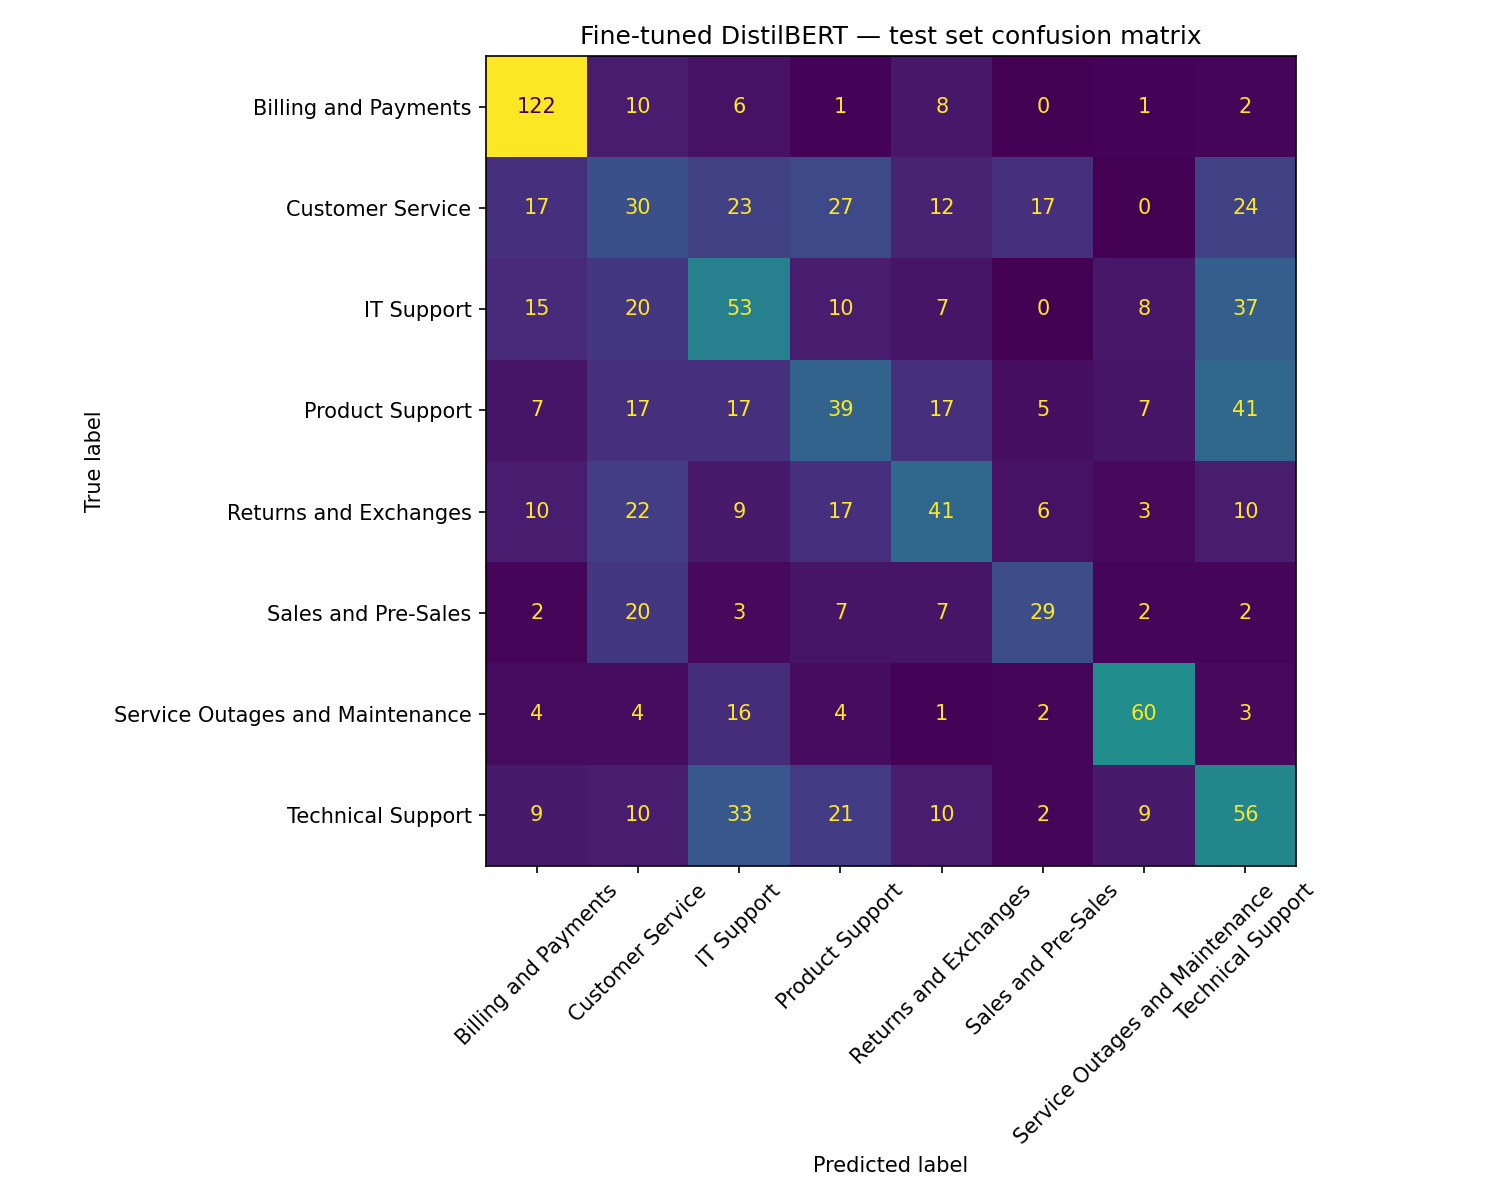

In [7]:
from IPython.display import Image; Image('finetune/results/confusion_matrix.png')

## 4. Training curves

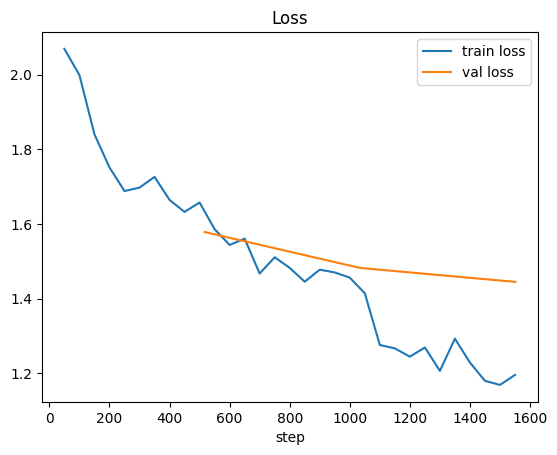

In [8]:
import pandas as pd, matplotlib.pyplot as plt
log = pd.read_csv('finetune/outputs/distilbert-ticket-queue/training_log.csv')
ax = log.dropna(subset=['loss']).plot(x='step', y='loss', label='train loss')
log.dropna(subset=['eval_loss']).plot(x='step', y='eval_loss', ax=ax, label='val loss'); plt.title('Loss'); plt.show()

## 5. Download the model and results back to the repo

In [9]:
!zip -qr finetuned_model.zip finetune/outputs finetune/results data/processed/labels.json
from google.colab import files; files.download('finetuned_model.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 6. Publish the model to the Hugging Face Hub (used by the live Space)
Set `CLASSIFIER_MODEL=<your-user>/distilbert-ticket-queue` as a Space variable afterwards.

In [11]:
from huggingface_hub import notebook_login; notebook_login()   # WRITE token
from transformers import AutoModelForSequenceClassification, AutoTokenizer
repo = 'vaikunths/distilbert-ticket-queue'
path = 'finetune/outputs/distilbert-ticket-queue'
AutoModelForSequenceClassification.from_pretrained(path).push_to_hub(repo)
AutoTokenizer.from_pretrained(path).push_to_hub(repo)

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...36dmrta/model.safetensors:   0%|          |  564kB /  268MB            

README.md: 0.00B [00:00, ?B/s]

CommitInfo(commit_url='https://huggingface.co/vaikunths/distilbert-ticket-queue/commit/fdb2ba782b322e35119fc4ecf0aca8ff61d563ad', commit_message='Upload tokenizer', commit_description='', oid='fdb2ba782b322e35119fc4ecf0aca8ff61d563ad', pr_url=None, repo_url=RepoUrl('https://huggingface.co/vaikunths/distilbert-ticket-queue', endpoint='https://huggingface.co', repo_type='model', repo_id='vaikunths/distilbert-ticket-queue'), pr_revision=None, pr_num=None)